In [18]:
import sys

In [19]:
sys.path.append("..")
from wavelet_transform.utils.save_plots import save_figure

from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.utils.kmeans_results as results

Bubble dynamics results

In [24]:
# Get bubble dynamics results
R_init = 10e-6
frequency = 2e6
pac = 1e6

exp_ids = [f"{R_init}_{frequency}_{pac}" for pac, R_init in [(1e6, 10e-6), (10e6, 1e-6)]]
exp_results = [results.get_data(result_id) for result_id in exp_ids]

exp_labels = ["stable", "transient"]  # Legend for final plot

# label_maps = [
#     {0: "broadband", 1: "measurement noise", 2: "fundamental"},
#     {0: "broadband", 1: "fundamental", 2: "measurement noise"}
# ]

In [26]:
print(exp_results[1].keys())

dict_keys(['data', 'tr_obj', 'centers', 'labels', 'sampling rate', 'freq_threshold', 'raw_data', 'bd_params'])


Results for other datasets

In [16]:
# # Get results from experiment number
# exp_number = 9  # 9, 15, 55
# result_id = str(exp_number)
# frequency = 2e6

# exp_ids = [9, 15, 55]
# exp_results = [results.get_data(result_id) for result_id in exp_ids]
# label_maps = [
#     {0: "broadband", 1: "measurement", 2:"fundamental"},
#     {0: "broadband", 1: "harmonic", 2:"measurement", 3: "fundamental", 4:"transient"},
#     {0: "measurement", 1: "broadband", 2: "fundamental"}
# ]

In [17]:
# # Get PCD results
# voltage = 120
# pcd_number = 10
# result_id = f"{voltage}_{pcd_number}"
# frequency = 1.1e6

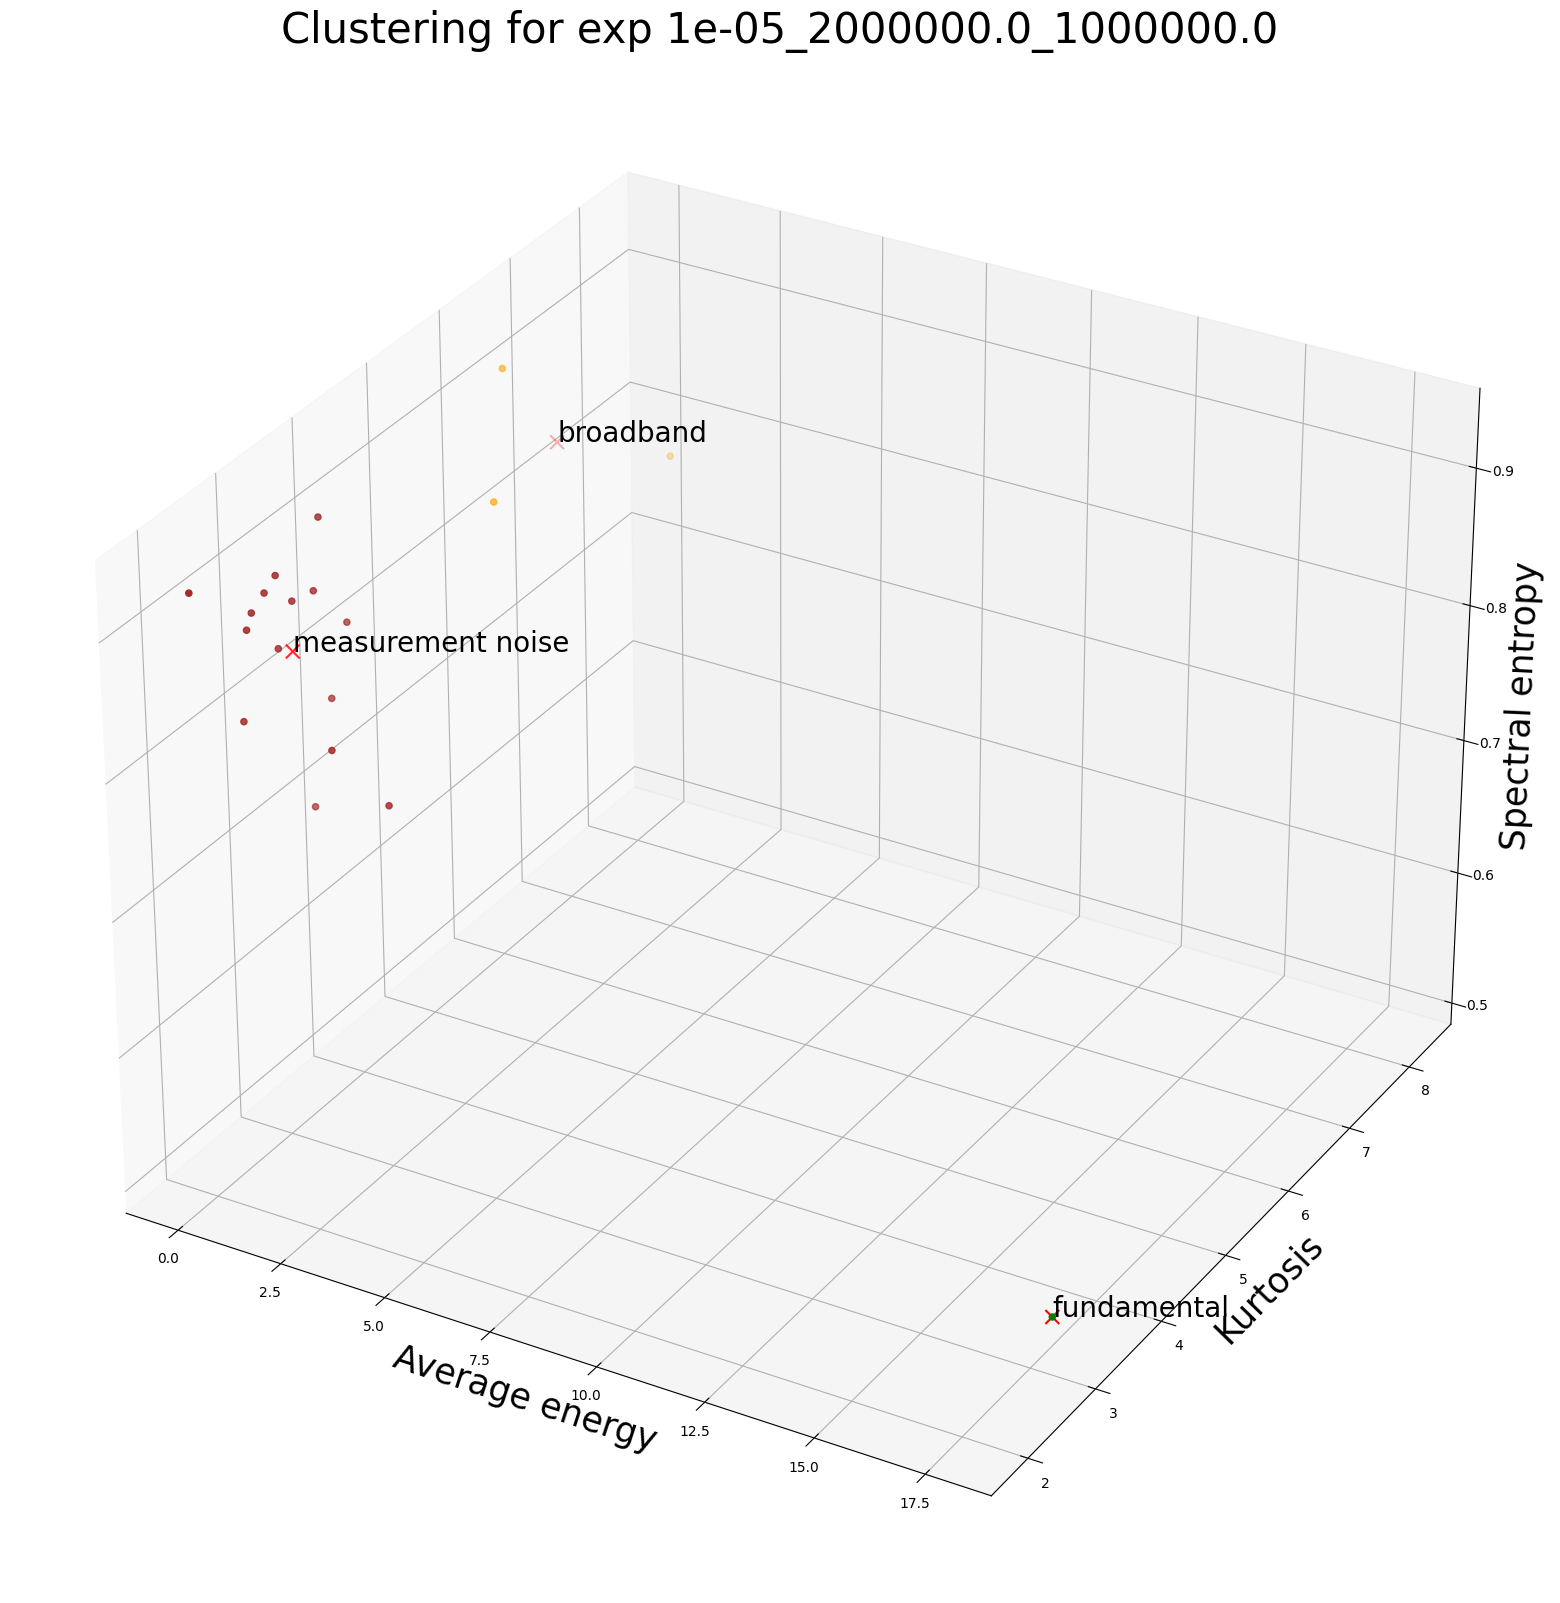

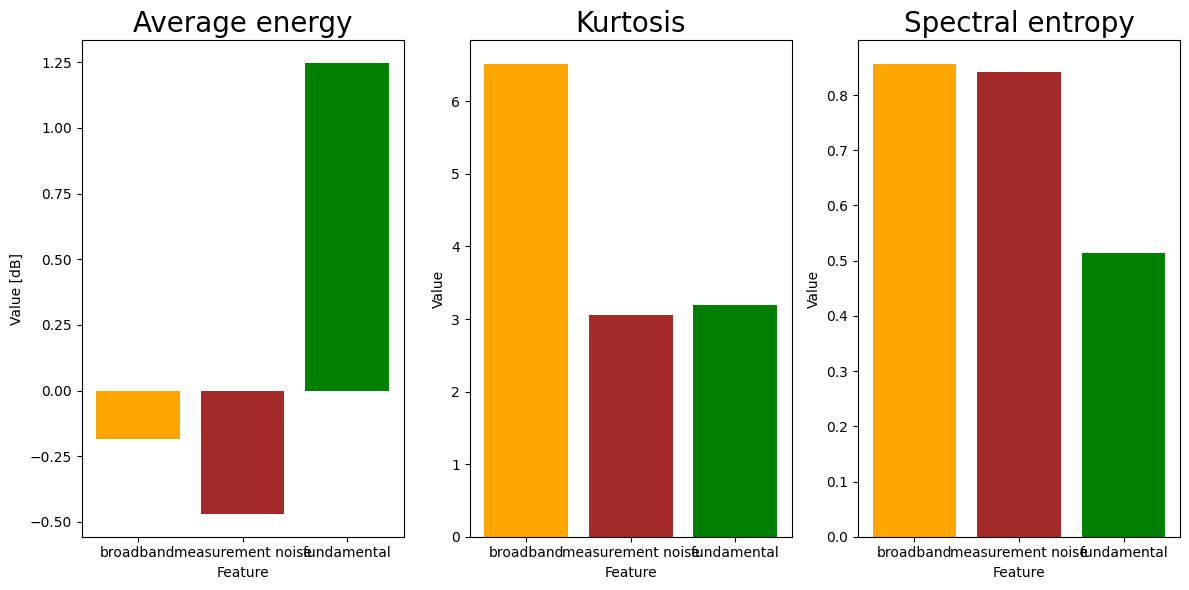

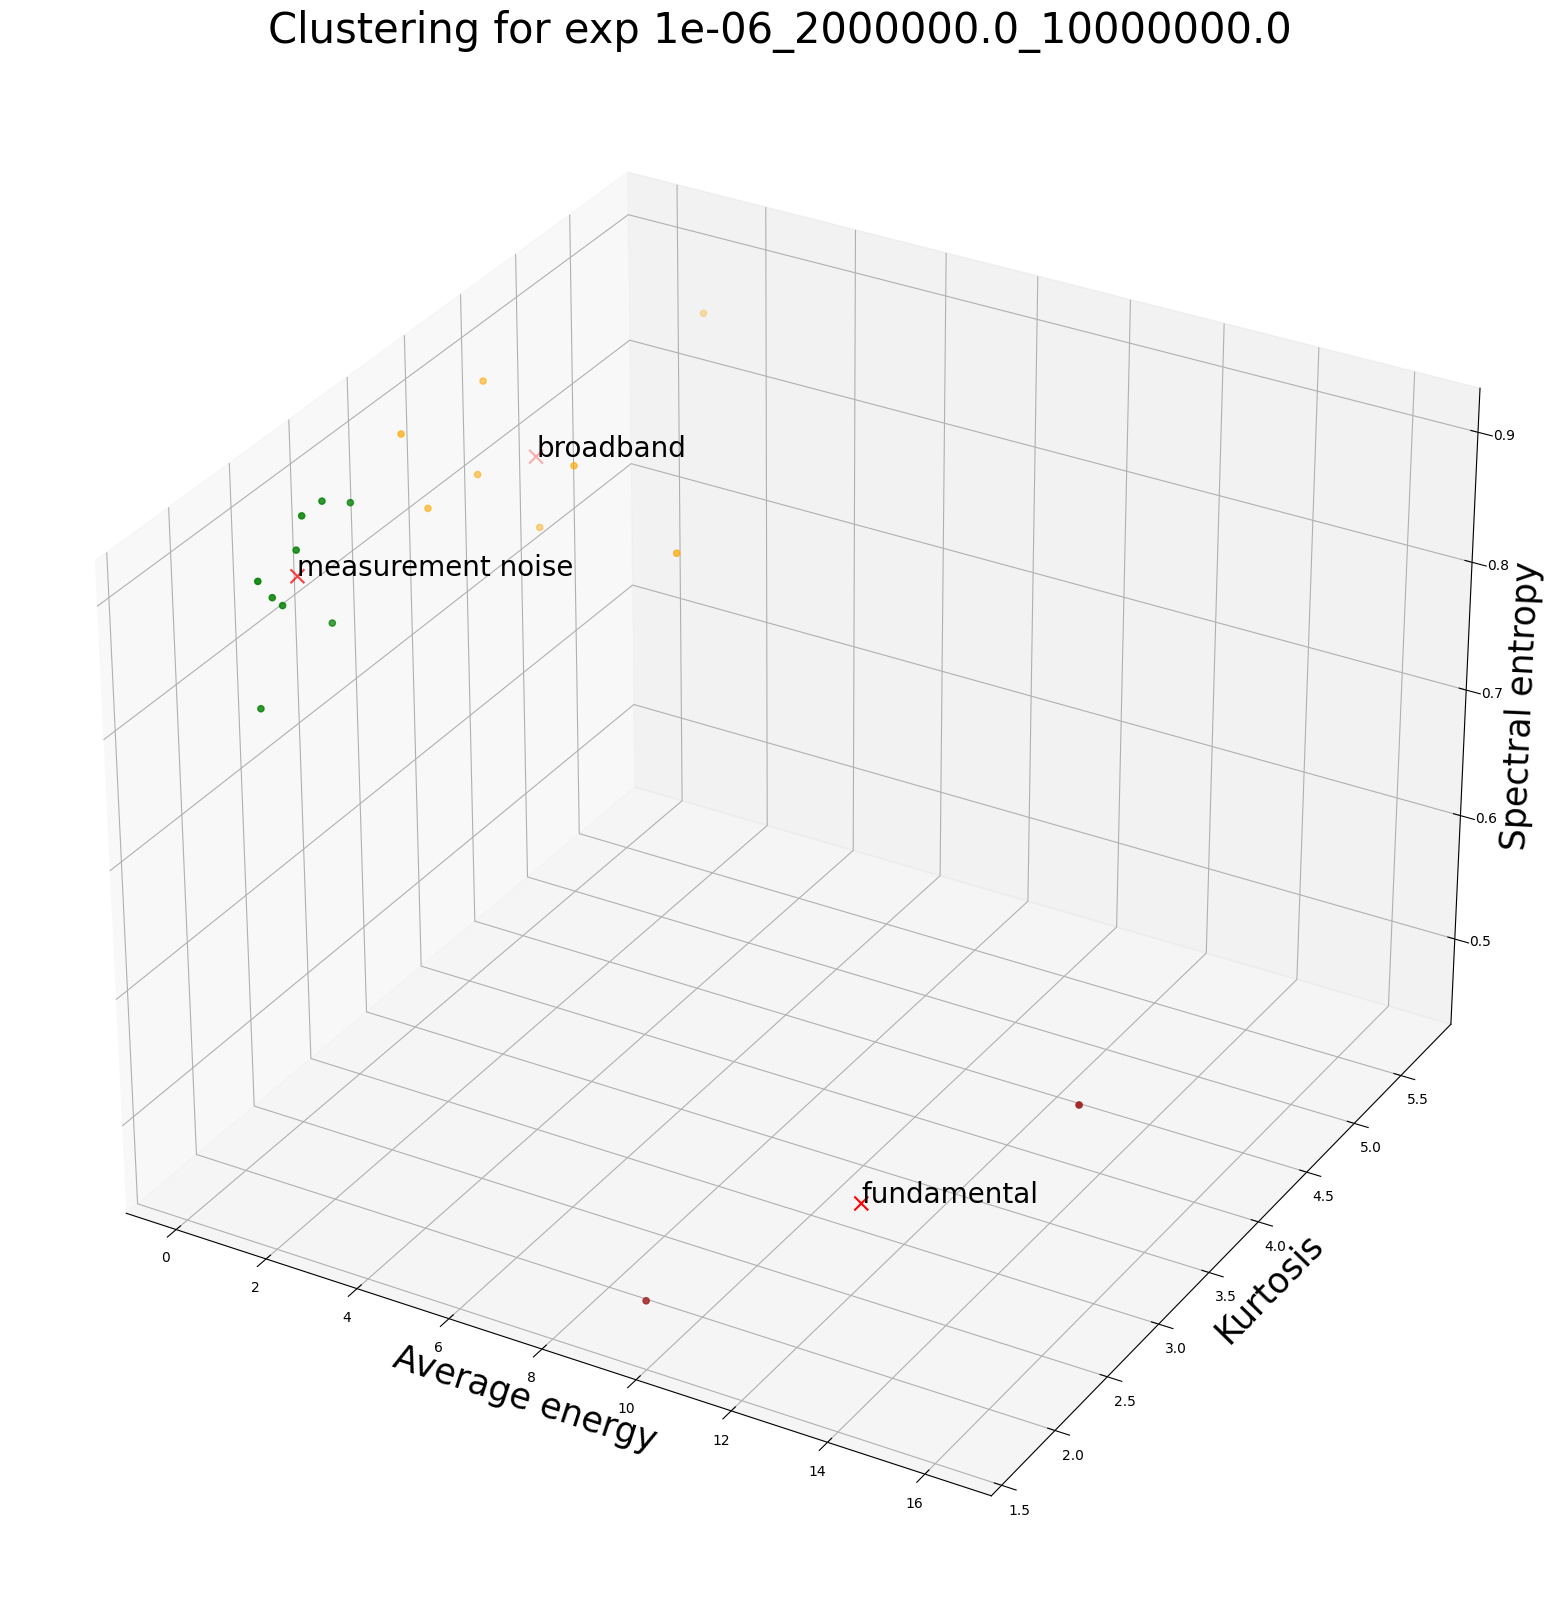

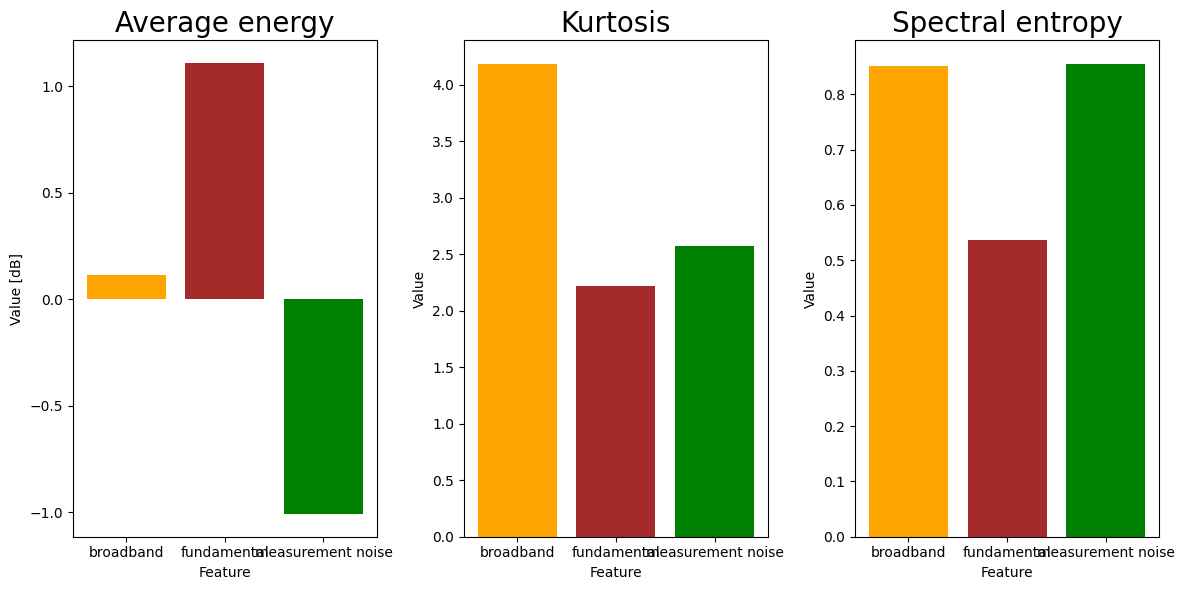

In [18]:
# Keep track of all results for combined plot in next cell
centers_list = []  # initialise list of centroid values
metrics_list = []

required_info = ["data_train", "tr_obj", "centers", "labels", "sampling_rate", "freq_threshold"]
# Plot separate clusterig results
for i, r in enumerate(exp_results):
    label_map = label_maps[i]
    # unpack results
    data_train, tr_obj, centers, labels, sampling_rate, freq_threshold = (
        tuple(r[i] for i in required_info)
    )
    fig = plot.plot_clustering(
        data_train, centers, labels, 
        title=f"Clustering for exp {exp_ids[i]}", label_map=label_map
    )
    centers_list.append(centers)

    # save_figure(fig, f"clustering_{result_id}")

    # Plot centroid metrics
    classifying_metrics = data_train.columns.to_list()
    metrics_list.append(classifying_metrics)
    fig = plot.plot_centers(classifying_metrics, centers, label_map)

    # save_figure(fig, f"centroids_{result_id}")

    # Set clusters to None to plot all of them, otherwise, plot a list of int
    fig = plot.plot_fft_by_group(
        tr_obj, labels, no_clusters=None, sampling_rate=sampling_rate,
        clusters=None, xlim=10, fundamental_freq=frequency,
        freq_threshold=freq_threshold, label_map=label_map
    )

    fig = plot.plot_reconstructions_by_group(
        tr_obj, labels, no_clusters=None, t_plot=sampling_rate, 
        freq_threshold=freq_threshold, label_map=label_map
    )

- change legend to stable and transient
- add error bars for multiple repetitions of the same experiment

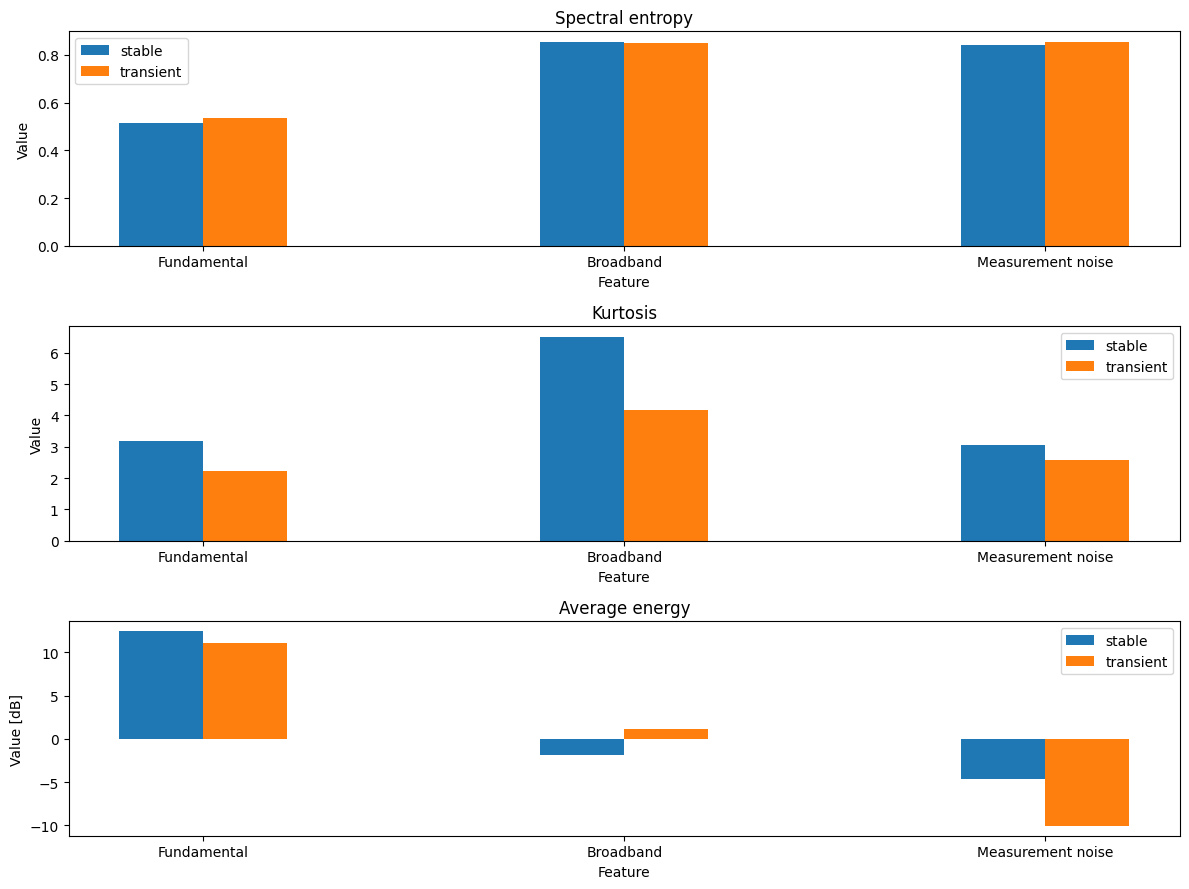

In [20]:
# Change exp_ids to label the transient and stable signals respectively.
fig = plot.plot_multiple_centers(metrics_list, centers_list, label_maps, exp_labels, bar_width=0.2)